#Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Current working directory:", Path.cwd())

Current working directory: c:\Users\User\Desktop\Customer_Churn_Prediction\notebooks


#Locate project folders

In [2]:
cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    cwd.parent.parent
]

PROJECT_ROOT = None

for candidate in candidate_roots:
    expected_file = (
        candidate
        / "data"
        / "processed"
        / "X_train.csv"
    )

    if expected_file.exists():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find X_train.csv. "
        "Please run 03_preprocessing.ipynb first."
    )

DATA_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
)

MODEL_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "models"
)

METRIC_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "metrics"
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

METRIC_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Project root:", PROJECT_ROOT.resolve())
print("Data directory:", DATA_DIR.resolve())

Project root: C:\Users\User\Desktop\Customer_Churn_Prediction
Data directory: C:\Users\User\Desktop\Customer_Churn_Prediction\data\processed


#Load training and testing data

In [3]:
X_train = pd.read_csv(
    DATA_DIR / "X_train.csv"
)

X_test = pd.read_csv(
    DATA_DIR / "X_test.csv"
)

y_train = pd.read_csv(
    DATA_DIR / "y_train.csv"
)["Churn"]

y_test = pd.read_csv(
    DATA_DIR / "y_test.csv"
)["Churn"]

test_customer_ids = pd.read_csv(
    DATA_DIR / "test_customer_ids.csv"
)["customerID"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print(
    "Test customer IDs:",
    test_customer_ids.shape
)

X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)
Test customer IDs: (1409,)


#Check target distribution

In [4]:
print("Training target distribution:")

print(
    y_train.value_counts(
        normalize=True
    )
    .mul(100)
    .round(2)
)

print("\nTesting target distribution:")

print(
    y_test.value_counts(
        normalize=True
    )
    .mul(100)
    .round(2)
)

Training target distribution:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


In [6]:
import joblib
from pathlib import Path

PREPROCESSOR_PATH = (
    MODEL_DIR
    / "preprocessor.joblib"
)

print("Preprocessor path:", PREPROCESSOR_PATH)
print("File exists:", PREPROCESSOR_PATH.exists())

preprocessor = joblib.load(
    PREPROCESSOR_PATH
)

print("Preprocessor loaded successfully.")

Preprocessor path: c:\Users\User\Desktop\Customer_Churn_Prediction\outputs\models\preprocessor.joblib
File exists: True
Preprocessor loaded successfully.


#Transform the datasets

In [7]:
X_train_transformed = (
    preprocessor.transform(
        X_train
    )
)

X_test_transformed = (
    preprocessor.transform(
        X_test
    )
)

print(
    "Transformed training shape:",
    X_train_transformed.shape
)

print(
    "Transformed testing shape:",
    X_test_transformed.shape
)

Transformed training shape: (5634, 46)
Transformed testing shape: (1409, 46)


Model 1 — Logistic Regression

Cell 7 — Train Logistic Regression

In [8]:
logistic_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(
    X_train_transformed,
    y_train
)

print(
    "Logistic Regression training completed."
)

Logistic Regression training completed.


#Logistic Regression predictions

In [9]:
lr_predictions = (
    logistic_model.predict(
        X_test_transformed
    )
)

lr_probabilities = (
    logistic_model.predict_proba(
        X_test_transformed
    )[:, 1]
)

print(
    "Predictions completed."
)

Predictions completed.


#Logistic Regression classification report

In [10]:
print(
    "LOGISTIC REGRESSION"
)

print(
    "=" * 60
)

print(
    classification_report(
        y_test,
        lr_predictions,
        target_names=[
            "No Churn",
            "Churn"
        ],
        zero_division=0
    )
)

LOGISTIC REGRESSION
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



Model 2 — Random Forest

#Train Random Forest

In [11]:
random_forest_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

random_forest_model.fit(
    X_train_transformed,
    y_train
)

print(
    "Random Forest training completed."
)

Random Forest training completed.


#Random Forest predictions

In [12]:
rf_predictions = (
    random_forest_model.predict(
        X_test_transformed
    )
)

rf_probabilities = (
    random_forest_model.predict_proba(
        X_test_transformed
    )[:, 1]
)

print(
    "Predictions completed."
)

Predictions completed.


#Random Forest classification report

In [13]:
print(
    "RANDOM FOREST"
)

print(
    "=" * 60
)

print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=[
            "No Churn",
            "Churn"
        ],
        zero_division=0
    )
)

RANDOM FOREST
              precision    recall  f1-score   support

    No Churn       0.82      0.90      0.86      1035
       Churn       0.63      0.47      0.54       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.70      1409
weighted avg       0.77      0.79      0.77      1409



#Compare both models

In [14]:
def calculate_metrics(
    model_name,
    actual,
    predicted,
    probability
):

    return {
        "Model": model_name,

        "Accuracy":
            accuracy_score(
                actual,
                predicted
            ),

        "Precision":
            precision_score(
                actual,
                predicted,
                zero_division=0
            ),

        "Recall":
            recall_score(
                actual,
                predicted,
                zero_division=0
            ),

        "F1_Score":
            f1_score(
                actual,
                predicted,
                zero_division=0
            ),

        "ROC_AUC":
            roc_auc_score(
                actual,
                probability
            )
    }

#Create model comparison

In [15]:
model_results = []

model_results.append(
    calculate_metrics(
        "Logistic Regression",
        y_test,
        lr_predictions,
        lr_probabilities
    )
)

model_results.append(
    calculate_metrics(
        "Random Forest",
        y_test,
        rf_predictions,
        rf_probabilities
    )
)

model_comparison = pd.DataFrame(
    model_results
)

model_comparison

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,0.738112,0.504303,0.783422,0.613613,0.841502
1,Random Forest,0.785664,0.628571,0.470588,0.538226,0.821836


#Rounded comparison table

In [17]:
display_results = (
    model_comparison.copy()
)

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score",
    "ROC_AUC"
]

display_results[
    metric_columns
] = (
    display_results[
        metric_columns
    ]
    .round(4)
)

display_results

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8415
1,Random Forest,0.7857,0.6286,0.4706,0.5382,0.8218


#Save comparison table

In [18]:
MODEL_COMPARISON_PATH = (
    METRIC_DIR
    / "model_comparison.csv"
)

model_comparison.to_csv(
    MODEL_COMPARISON_PATH,
    index=False
)

print(
    "Saved:",
    MODEL_COMPARISON_PATH
)

Saved: c:\Users\User\Desktop\Customer_Churn_Prediction\outputs\metrics\model_comparison.csv


#Logistic Regression confusion matrix

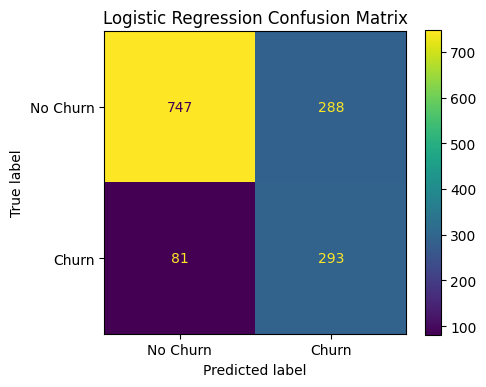

Saved: c:\Users\User\Desktop\Customer_Churn_Prediction\outputs\figures\09_logistic_regression_confusion_matrix.png


In [19]:
lr_cm = confusion_matrix(
    y_test,
    lr_predictions
)

fig, ax = plt.subplots(
    figsize=(5, 4)
)

ConfusionMatrixDisplay(
    confusion_matrix=lr_cm,
    display_labels=[
        "No Churn",
        "Churn"
    ]
).plot(
    ax=ax
)

plt.title(
    "Logistic Regression Confusion Matrix"
)

plt.tight_layout()

plot_path = (
    FIGURE_DIR
    / "09_logistic_regression_confusion_matrix.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    plot_path
)

#Random Forest confusion matrix

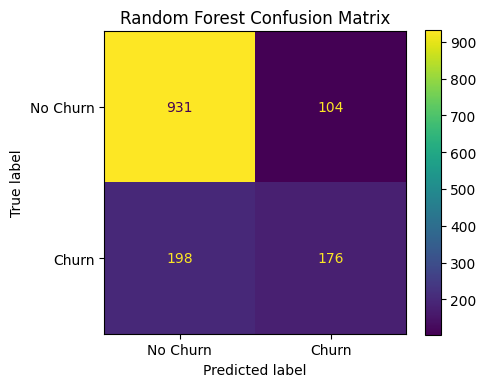

Saved: c:\Users\User\Desktop\Customer_Churn_Prediction\outputs\figures\10_random_forest_confusion_matrix.png


In [20]:
rf_cm = confusion_matrix(
    y_test,
    rf_predictions
)

fig, ax = plt.subplots(
    figsize=(5, 4)
)

ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=[
        "No Churn",
        "Churn"
    ]
).plot(
    ax=ax
)

plt.title(
    "Random Forest Confusion Matrix"
)

plt.tight_layout()

plot_path = (
    FIGURE_DIR
    / "10_random_forest_confusion_matrix.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    plot_path
)

#ROC curves

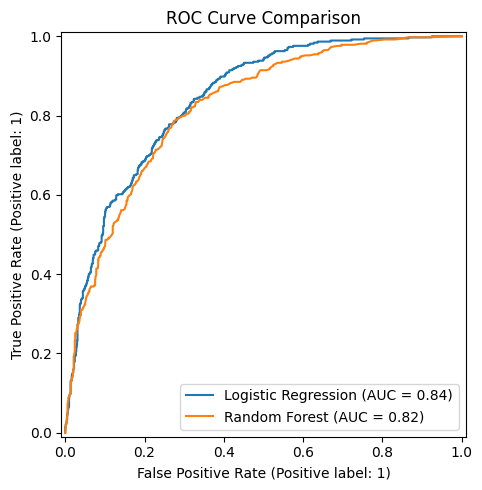

Saved: c:\Users\User\Desktop\Customer_Churn_Prediction\outputs\figures\11_roc_curve_comparison.png


In [21]:
fig, ax = plt.subplots(
    figsize=(7, 5)
)

RocCurveDisplay.from_predictions(
    y_test,
    lr_probabilities,
    name="Logistic Regression",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    rf_probabilities,
    name="Random Forest",
    ax=ax
)

plt.title(
    "ROC Curve Comparison"
)

plt.tight_layout()

plot_path = (
    FIGURE_DIR
    / "11_roc_curve_comparison.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    plot_path
)

#Obtain feature names

In [22]:
feature_names = (
    preprocessor
    .get_feature_names_out()
)

print(
    "Number of transformed features:",
    len(feature_names)
)

Number of transformed features: 46


#Calculate Random Forest importance

In [23]:
feature_importance = pd.DataFrame({
    "Feature":
        feature_names,

    "Importance":
        random_forest_model
        .feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

feature_importance.head(20)

,Feature,Importance
0,num__TotalCharges,0.141983
1,num__tenure,0.129347
2,num__MonthlyCharges,0.121771
3,cat__Contract_Month-to-month,0.069567
4,cat__OnlineSecurity_No,0.037229
5,cat__Contract_Two year,0.033122
6,cat__TechSupport_No,0.032858
7,cat__PaymentMethod_Electronic check,0.027665
8,cat__InternetService_Fiber optic,0.027030
9,cat__OnlineBackup_No,0.016827


#Plot top 15 churn features

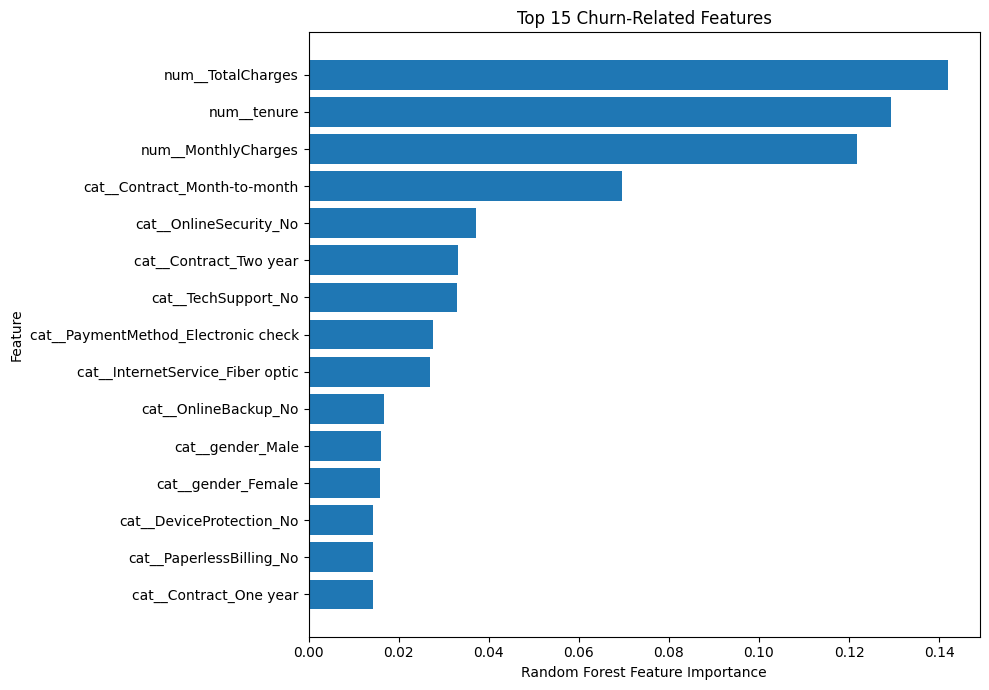

Saved: c:\Users\User\Desktop\Customer_Churn_Prediction\outputs\figures\12_random_forest_feature_importance.png


In [24]:
top_features = (
    feature_importance
    .head(15)
    .sort_values(
        "Importance",
        ascending=True
    )
)

plt.figure(
    figsize=(10, 7)
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title(
    "Top 15 Churn-Related Features"
)

plt.xlabel(
    "Random Forest Feature Importance"
)

plt.ylabel(
    "Feature"
)

plt.tight_layout()

plot_path = (
    FIGURE_DIR
    / "12_random_forest_feature_importance.png"
)

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    plot_path
)

#Save feature importance

In [25]:
feature_importance.to_csv(
    METRIC_DIR
    / "random_forest_feature_importance.csv",
    index=False
)

print(
    "Feature importance saved."
)

Feature importance saved.


#Logistic Regression interpretation

#Logistic Regression coefficients

In [26]:
lr_coefficients = pd.DataFrame({
    "Feature":
        feature_names,

    "Coefficient":
        logistic_model.coef_[0]
})

lr_coefficients[
    "Absolute_Coefficient"
] = (
    lr_coefficients[
        "Coefficient"
    ].abs()
)

lr_coefficients = (
    lr_coefficients
    .sort_values(
        "Absolute_Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

lr_coefficients.head(20)

,Feature,Coefficient,Absolute_Coefficient
0,num__tenure,-1.141091,1.141091
1,cat__Contract_Two year,-0.766446,0.766446
2,cat__InternetService_Fiber optic,0.715756,0.715756
3,num__MonthlyCharges,-0.677256,0.677256
4,cat__Contract_Month-to-month,0.662997,0.662997
5,cat__InternetService_DSL,-0.617657,0.617657
6,num__TotalCharges,0.474357,0.474357
7,cat__StreamingMovies_Yes,0.282577,0.282577
8,cat__DeviceProtection_No internet service,-0.270347,0.270347
9,cat__OnlineSecurity_No internet service,-0.270347,0.270347


#Save Logistic Regression coefficients

In [27]:
lr_coefficients.to_csv(
    METRIC_DIR
    / "logistic_regression_coefficients.csv",
    index=False
)

print(
    "Logistic Regression coefficients saved."
)

Logistic Regression coefficients saved.


#High-risk customer predictions

In [28]:
#Create customer prediction table
customer_predictions = X_test.copy()

customer_predictions.insert(
    0,
    "customerID",
    test_customer_ids.values
)

customer_predictions[
    "ActualChurn"
] = y_test.values

customer_predictions[
    "LogisticChurnProbability"
] = lr_probabilities

customer_predictions[
    "RandomForestChurnProbability"
] = rf_probabilities

customer_predictions[
    "RandomForestPrediction"
] = rf_predictions

customer_predictions.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,ActualChurn,LogisticChurnProbability,RandomForestChurnProbability,RandomForestPrediction
0,4376-KFVRS,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20,0,0.117088,0.000000,0
1,2754-SDJRD,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,No,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,0,0.852378,0.736667,1
2,9917-KWRBE,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20,0,0.146488,0.060000,0
3,0365-GXEZS,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,Yes,Yes,No,No,Month-to-month,No,Electronic check,78.20,1468.75,0,0.660506,0.316667,0
4,9385-NXKDA,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,0,0.060881,0.003333,0


#Convert labels for readability

In [29]:
customer_predictions[
    "ActualChurnLabel"
] = (
    customer_predictions[
        "ActualChurn"
    ]
    .map({
        0: "No",
        1: "Yes"
    })
)

customer_predictions[
    "PredictedChurnLabel"
] = (
    customer_predictions[
        "RandomForestPrediction"
    ]
    .map({
        0: "No",
        1: "Yes"
    })
)

#Find highest-risk customers

In [30]:
high_risk_customers = (
    customer_predictions
    .sort_values(
        "RandomForestChurnProbability",
        ascending=False
    )
)

high_risk_customers[
    [
        "customerID",
        "Contract",
        "tenure",
        "InternetService",
        "PaymentMethod",
        "MonthlyCharges",
        "RandomForestChurnProbability",
        "ActualChurnLabel"
    ]
].head(20)

,customerID,Contract,tenure,InternetService,PaymentMethod,MonthlyCharges,RandomForestChurnProbability,ActualChurnLabel
629,5542-TBBWB,Month-to-month,1,Fiber optic,Electronic check,69.90,1.000000,No
618,9248-OJYKK,Month-to-month,1,Fiber optic,Electronic check,76.45,1.000000,Yes
1252,9804-ICWBG,Month-to-month,1,Fiber optic,Electronic check,69.90,1.000000,Yes
1289,8375-DKEBR,Month-to-month,1,Fiber optic,Electronic check,69.60,0.993333,Yes
341,1820-TQVEV,Month-to-month,1,Fiber optic,Electronic check,69.55,0.983333,Yes
171,2514-GINMM,Month-to-month,1,Fiber optic,Electronic check,79.50,0.983333,Yes
38,4415-IJZTP,Month-to-month,1,Fiber optic,Electronic check,74.50,0.966667,Yes
1175,6861-XWTWQ,Month-to-month,7,Fiber optic,Electronic check,99.25,0.963333,Yes
1178,0841-NULXI,Month-to-month,1,DSL,Electronic check,35.55,0.963333,Yes
634,1751-NCDLI,Month-to-month,46,Fiber optic,Electronic check,98.85,0.963333,No


#Create a high-risk flag

In [31]:
customer_predictions[
    "RiskLevel"
] = np.where(
    customer_predictions[
        "RandomForestChurnProbability"
    ] >= 0.70,
    "High Risk",
    np.where(
        customer_predictions[
            "RandomForestChurnProbability"
        ] >= 0.40,
        "Medium Risk",
        "Low Risk"
    )
)

customer_predictions[
    "RiskLevel"
].value_counts()

RiskLevel
Low Risk       1017
Medium Risk     253
High Risk       139
Name: count, dtype: int64

#Save customer predictions

In [32]:
customer_predictions.to_csv(
    METRIC_DIR
    / "customer_churn_predictions.csv",
    index=False
)

print(
    "Customer predictions saved."
)

Customer predictions saved.


#Save trained models


In [33]:
#Save Logistic Regression
LOGISTIC_MODEL_PATH = (
    MODEL_DIR
    / "logistic_regression.joblib"
)

joblib.dump(
    logistic_model,
    LOGISTIC_MODEL_PATH
)

print(
    "Saved:",
    LOGISTIC_MODEL_PATH
)

Saved: c:\Users\User\Desktop\Customer_Churn_Prediction\outputs\models\logistic_regression.joblib


In [34]:
#Save Random Forest
RANDOM_FOREST_PATH = (
    MODEL_DIR
    / "random_forest.joblib"
)

joblib.dump(
    random_forest_model,
    RANDOM_FOREST_PATH
)

print(
    "Saved:",
    RANDOM_FOREST_PATH
)

Saved: c:\Users\User\Desktop\Customer_Churn_Prediction\outputs\models\random_forest.joblib


#Determine best model

In [35]:
#Best ROC-AUC model
best_auc_model = (
    model_comparison
    .sort_values(
        "ROC_AUC",
        ascending=False
    )
    .iloc[0]
)

print(
    "BEST MODEL BASED ON ROC-AUC"
)

print(
    "=" * 60
)

print(
    "Model:",
    best_auc_model["Model"]
)

print(
    f"Accuracy: "
    f"{best_auc_model['Accuracy']:.4f}"
)

print(
    f"Precision: "
    f"{best_auc_model['Precision']:.4f}"
)

print(
    f"Recall: "
    f"{best_auc_model['Recall']:.4f}"
)

print(
    f"F1 Score: "
    f"{best_auc_model['F1_Score']:.4f}"
)

print(
    f"ROC-AUC: "
    f"{best_auc_model['ROC_AUC']:.4f}"
)

BEST MODEL BASED ON ROC-AUC
Model: Logistic Regression
Accuracy: 0.7381
Precision: 0.5043
Recall: 0.7834
F1 Score: 0.6136
ROC-AUC: 0.8415


#Compare churn recall specifically

In [36]:
recall_comparison = (
    model_comparison[
        [
            "Model",
            "Recall"
        ]
    ]
    .sort_values(
        "Recall",
        ascending=False
    )
)

recall_comparison

,Model,Recall
0,Logistic Regression,0.783422
1,Random Forest,0.470588


#Final output summary

In [37]:
#Print results
print(
    "MACHINE LEARNING SUMMARY"
)

print(
    "=" * 70
)

for _, row in model_comparison.iterrows():

    print(
        f"\n{row['Model']}"
    )

    print(
        f"Accuracy : "
        f"{row['Accuracy']:.4f}"
    )

    print(
        f"Precision: "
        f"{row['Precision']:.4f}"
    )

    print(
        f"Recall   : "
        f"{row['Recall']:.4f}"
    )

    print(
        f"F1 Score : "
        f"{row['F1_Score']:.4f}"
    )

    print(
        f"ROC-AUC  : "
        f"{row['ROC_AUC']:.4f}"
    )

MACHINE LEARNING SUMMARY

Logistic Regression
Accuracy : 0.7381
Precision: 0.5043
Recall   : 0.7834
F1 Score : 0.6136
ROC-AUC  : 0.8415

Random Forest
Accuracy : 0.7857
Precision: 0.6286
Recall   : 0.4706
F1 Score : 0.5382
ROC-AUC  : 0.8218


In [38]:
#Show top 10 features
print(
    "TOP 10 RANDOM FOREST FEATURES"
)

print(
    "=" * 70
)

display(
    feature_importance.head(10)
)

TOP 10 RANDOM FOREST FEATURES


,Feature,Importance
0,num__TotalCharges,0.141983
1,num__tenure,0.129347
2,num__MonthlyCharges,0.121771
3,cat__Contract_Month-to-month,0.069567
4,cat__OnlineSecurity_No,0.037229
5,cat__Contract_Two year,0.033122
6,cat__TechSupport_No,0.032858
7,cat__PaymentMethod_Electronic check,0.027665
8,cat__InternetService_Fiber optic,0.027030
9,cat__OnlineBackup_No,0.016827


In [39]:
#Verify all generated outputs
files_to_check = [
    MODEL_DIR
    / "logistic_regression.joblib",

    MODEL_DIR
    / "random_forest.joblib",

    METRIC_DIR
    / "model_comparison.csv",

    METRIC_DIR
    / "random_forest_feature_importance.csv",

    METRIC_DIR
    / "logistic_regression_coefficients.csv",

    METRIC_DIR
    / "customer_churn_predictions.csv",

    FIGURE_DIR
    / "09_logistic_regression_confusion_matrix.png",

    FIGURE_DIR
    / "10_random_forest_confusion_matrix.png",

    FIGURE_DIR
    / "11_roc_curve_comparison.png",

    FIGURE_DIR
    / "12_random_forest_feature_importance.png"
]

for file in files_to_check:

    print(
        file.name,
        "→",
        file.exists()
    )

logistic_regression.joblib → True
random_forest.joblib → True
model_comparison.csv → True
random_forest_feature_importance.csv → True
logistic_regression_coefficients.csv → True
customer_churn_predictions.csv → True
09_logistic_regression_confusion_matrix.png → True
10_random_forest_confusion_matrix.png → True
11_roc_curve_comparison.png → True
12_random_forest_feature_importance.png → True


In [40]:
#Logistic 
customer_predictions = X_test.copy()

customer_predictions.insert(
    0,
    "customerID",
    test_customer_ids.values
)

customer_predictions[
    "ActualChurn"
] = y_test.values

customer_predictions[
    "ChurnProbability"
] = lr_probabilities

customer_predictions[
    "PredictedChurn"
] = lr_predictions

customer_predictions[
    "ActualChurnLabel"
] = (
    customer_predictions[
        "ActualChurn"
    ]
    .map({
        0: "No",
        1: "Yes"
    })
)

customer_predictions[
    "PredictedChurnLabel"
] = (
    customer_predictions[
        "PredictedChurn"
    ]
    .map({
        0: "No",
        1: "Yes"
    })
)

In [41]:
customer_predictions[
    "RiskLevel"
] = np.where(
    customer_predictions[
        "ChurnProbability"
    ] >= 0.70,
    "High Risk",

    np.where(
        customer_predictions[
            "ChurnProbability"
        ] >= 0.40,
        "Medium Risk",
        "Low Risk"
    )
)

customer_predictions[
    "RiskLevel"
].value_counts()

RiskLevel
Low Risk       715
High Risk      373
Medium Risk    321
Name: count, dtype: int64

In [42]:
high_risk_customers = (
    customer_predictions
    .sort_values(
        "ChurnProbability",
        ascending=False
    )
)

high_risk_customers[
    [
        "customerID",
        "Contract",
        "tenure",
        "InternetService",
        "PaymentMethod",
        "MonthlyCharges",
        "ChurnProbability",
        "ActualChurnLabel"
    ]
].head(20)

,customerID,Contract,tenure,InternetService,PaymentMethod,MonthlyCharges,ChurnProbability,ActualChurnLabel
1090,5178-LMXOP,Month-to-month,1,Fiber optic,Electronic check,95.10,0.937978,Yes
1221,0295-PPHDO,Month-to-month,1,Fiber optic,Electronic check,95.45,0.926779,Yes
1175,6861-XWTWQ,Month-to-month,7,Fiber optic,Electronic check,99.25,0.925977,Yes
1164,8884-ADFVN,Month-to-month,7,Fiber optic,Electronic check,101.95,0.922239,Yes
1109,1069-XAIEM,Month-to-month,1,Fiber optic,Electronic check,85.05,0.920495,Yes
889,2545-EBUPK,Month-to-month,2,Fiber optic,Electronic check,84.05,0.920278,No
1138,1400-MMYXY,Month-to-month,3,Fiber optic,Electronic check,105.90,0.920128,Yes
647,6023-YEBUP,Month-to-month,3,Fiber optic,Electronic check,100.95,0.919386,Yes
627,9057-SIHCH,Month-to-month,3,Fiber optic,Electronic check,96.60,0.919010,Yes
995,8161-QYMTT,Month-to-month,7,Fiber optic,Electronic check,94.10,0.918038,No


In [43]:
customer_predictions.to_csv(
    METRIC_DIR
    / "customer_churn_predictions.csv",
    index=False
)

print(
    "Customer churn predictions saved."
)

Customer churn predictions saved.


In [44]:
feature_importance.head(10)

,Feature,Importance
0,num__TotalCharges,0.141983
1,num__tenure,0.129347
2,num__MonthlyCharges,0.121771
3,cat__Contract_Month-to-month,0.069567
4,cat__OnlineSecurity_No,0.037229
5,cat__Contract_Two year,0.033122
6,cat__TechSupport_No,0.032858
7,cat__PaymentMethod_Electronic check,0.027665
8,cat__InternetService_Fiber optic,0.027030
9,cat__OnlineBackup_No,0.016827


## Important Customer Churn Characteristics

Random Forest feature importance identified several customer characteristics that were useful for predicting churn. The most influential variables were Total Charges, customer tenure, and Monthly Charges, followed by contract type, Online Security, Tech Support, payment method, Internet Service, and Online Backup.

These machine-learning findings are consistent with the exploratory analysis. Customers using month-to-month contracts had a churn rate of 42.71%, while Fiber Optic customers recorded a churn rate of 41.89%. Electronic Check customers had the highest payment-method churn rate at 45.29%.

Customer tenure was also strongly associated with churn. Churned customers had an average tenure of 17.98 months compared with 37.57 months among retained customers. In addition, churned customers had higher average monthly charges (74.44) than retained customers (61.27).

Random Forest feature importance indicates the predictive usefulness of each feature but does not by itself indicate whether that feature increases or decreases churn.

## Business Recommendations

### 1. Encourage Longer-Term Contracts
Month-to-month customers recorded the highest contract-related churn rate at 42.71%. The company could provide loyalty discounts, bundled services, or other incentives to encourage suitable month-to-month customers to move to one-year or two-year contracts.

### 2. Strengthen Early Customer Retention
Customers who churned had an average tenure of only 17.98 months compared with 37.57 months for retained customers. The company should therefore prioritize onboarding, proactive support, satisfaction checks, and targeted retention offers during the earlier stages of the customer relationship.

### 3. Review High-Charge and Fiber Optic Customer Experience
Churned customers had higher average monthly charges, while Fiber Optic customers showed a churn rate of 41.89%. The company should investigate pricing, service quality, reliability, and perceived value among Fiber Optic and higher-charge customer groups.

### 4. Target High-Risk Payment Segments
Electronic Check users recorded a churn rate of 45.29%. This segment could be targeted with retention campaigns and convenient alternatives such as automated or electronic payment options where appropriate.

### 5. Improve Support and Value-Added Services
The absence of Tech Support, Online Security, and Online Backup appeared among important predictive features. The company could investigate whether targeted support packages, onboarding assistance, or bundled service offers improve retention among these customer groups.

## Final Model Selection

Logistic Regression was selected as the preferred churn prediction model. Although Random Forest achieved higher overall accuracy (78.57%) and precision (62.86%), Logistic Regression achieved considerably higher recall (78.34% compared with 47.06%), a higher F1 score (0.6136 compared with 0.5382), and a higher ROC-AUC score (0.8415 compared with 0.8218).

In a customer churn scenario, recall is particularly important because customers who are incorrectly classified as unlikely to churn may leave before the company can take retention action. Therefore, Logistic Regression provides a more suitable balance for identifying customers who may require proactive retention efforts.

Random Forest was retained as a secondary model and used to analyse feature importance and identify customer characteristics associated with churn.